In [1]:
# SECTION 8: Build forecasting features (lags and rolling averages)

# Import libraries
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

# Load cleaned infrastructure data in time order
infra = pd.read_csv("data/clean_infrastructure.csv", parse_dates=["timestamp"])

infra = infra.sort_values("timestamp").reset_index(drop=True)

# Weekday indicator as a number
infra["is_weekday"] = (infra["day_type"] == "Weekday").astype(int)

# Metrics to forecast: success rates, latency, resource utilization
forecast_targets = ["neft_success_rate", "imps_success_rate", "rtgs_success_rate", "avg_transaction_processing_time_ms", "cpu_utilization", "memory_usage"]

# Lag and rolling-average features for each target, using only past minutes
for col in forecast_targets:
    for lag in [1, 5, 15, 60]:
        infra[col + "_lag" + str(lag)] = infra[col].shift(lag)
    infra[col + "_roll15"] = infra[col].shift(1).rolling(15).mean()
    infra[col + "_roll60"] = infra[col].shift(1).rolling(60).mean()

# Drop the first hour, which has no full history
forecast_df = infra.dropna().reset_index(drop=True)

# Time-ordered split: first 80% to train, last 20% to test
split = int(len(forecast_df) * 0.8)

print("Rows with full history :", len(forecast_df))
print("Train :", forecast_df["timestamp"].iloc[0], "to", forecast_df["timestamp"].iloc[split - 1])
print("Test :", forecast_df["timestamp"].iloc[split], "to", forecast_df["timestamp"].iloc[-1])
print("Feature columns created :", len(forecast_targets) * 6)

Rows with full history : 10020
Train : 2025-10-20 01:00:00 to 2025-10-25 14:35:00
Test : 2025-10-25 14:36:00 to 2025-10-26 23:59:00
Feature columns created : 36


                            target               model   RMSE    MAE
                 neft_success_rate Naive (last minute)  1.629  1.328
                 neft_success_rate   Linear Regression  1.159  1.002
                 neft_success_rate       Random Forest  1.161  1.004
                 imps_success_rate Naive (last minute)  0.810  0.657
                 imps_success_rate   Linear Regression  0.581  0.503
                 imps_success_rate       Random Forest  0.586  0.507
                 rtgs_success_rate Naive (last minute)  0.402  0.329
                 rtgs_success_rate   Linear Regression  0.285  0.245
                 rtgs_success_rate       Random Forest  0.287  0.247
avg_transaction_processing_time_ms Naive (last minute) 33.535 24.308
avg_transaction_processing_time_ms   Linear Regression 26.791 20.937
avg_transaction_processing_time_ms       Random Forest 25.255 20.312
                   cpu_utilization Naive (last minute)  4.154  3.345
                   cpu_utilization

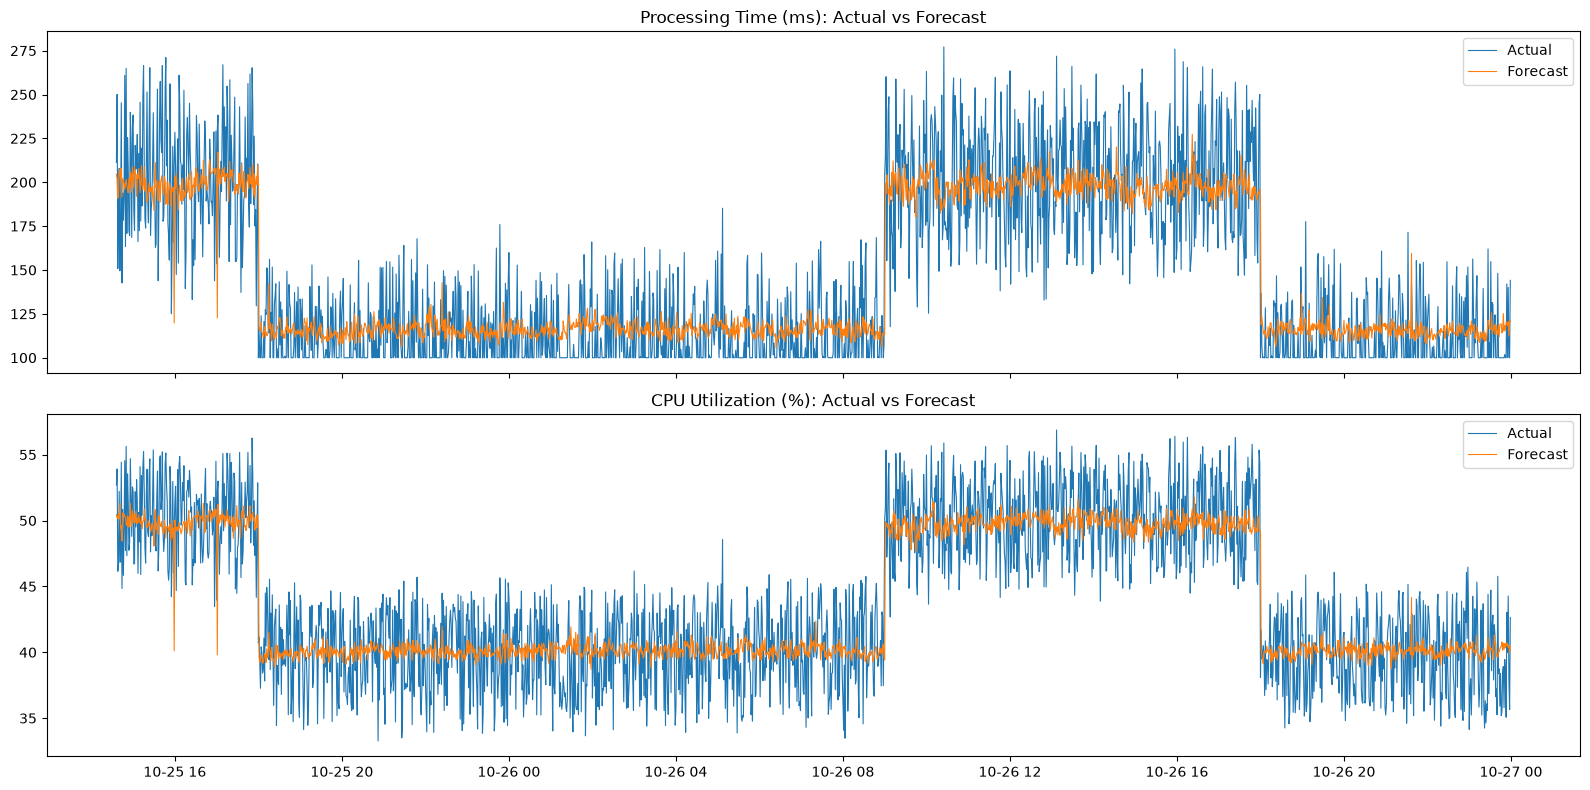

In [2]:
# SECTION 9: Forecast success rates, latency, and utilization

from sklearn.linear_model import LinearRegression

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error

# Feature list: every lag and rolling column plus time features
feature_cols = []
for col in forecast_targets:
    for suffix in ["_lag1", "_lag5", "_lag15", "_lag60", "_roll15", "_roll60"]:
        feature_cols.append(col + suffix)

feature_cols = feature_cols + ["hour", "is_weekday"]

# Time-ordered train and test features
X_train = forecast_df[feature_cols].iloc[:split]

X_test = forecast_df[feature_cols].iloc[split:]

# Train and score each model for each target
results = []
best_forecasters = {}
best_preds = {}

for target in forecast_targets:
    y_train = forecast_df[target].iloc[:split]
    y_test = forecast_df[target].iloc[split:]

    # Naive baseline: next minute equals last minute
    models = {"Naive (last minute)": None, "Linear Regression": LinearRegression(), "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)}

    best_rmse = None
    for name, model in models.items():
        if model is None:
            pred = forecast_df[target + "_lag1"].iloc[split:]
        else:
            model.fit(X_train, y_train)
            pred = model.predict(X_test)

        rmse = np.sqrt(mean_squared_error(y_test, pred))
        mae = mean_absolute_error(y_test, pred)
        results.append({"target": target, "model": name, "RMSE": round(rmse, 3), "MAE": round(mae, 3)})

        # Keep the trained model with the lowest RMSE
        if model is not None and (best_rmse is None or rmse < best_rmse):
            best_rmse = rmse
            best_forecasters[target] = model
            best_preds[target] = pred

# Results table
results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

print()
for target in forecast_targets:
    print("Best model for", target, ":", type(best_forecasters[target]).__name__)

# Actual vs forecast for latency and CPU over the test period
test_time = forecast_df["timestamp"].iloc[split:]

fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

axes[0].plot(test_time, forecast_df["avg_transaction_processing_time_ms"].iloc[split:], label="Actual", linewidth=0.8)
axes[0].plot(test_time, best_preds["avg_transaction_processing_time_ms"], label="Forecast", linewidth=0.8)
axes[0].set_title("Processing Time (ms): Actual vs Forecast")
axes[0].legend()

axes[1].plot(test_time, forecast_df["cpu_utilization"].iloc[split:], label="Actual", linewidth=0.8)
axes[1].plot(test_time, best_preds["cpu_utilization"], label="Forecast", linewidth=0.8)
axes[1].set_title("CPU Utilization (%): Actual vs Forecast")
axes[1].legend()

plt.tight_layout()
plt.show()

Class balance :
incident
0    9905
1     175
Name: count, dtype: int64

===== Decision Tree + SMOTE =====
Accuracy : 1.0 | F1 (incident) : 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1981
           1       1.00      1.00      1.00        35

    accuracy                           1.00      2016
   macro avg       1.00      1.00      1.00      2016
weighted avg       1.00      1.00      1.00      2016

Confusion matrix :
[[1981    0]
 [   0   35]]

===== Balanced Random Forest =====
Accuracy : 1.0 | F1 (incident) : 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1981
           1       1.00      1.00      1.00        35

    accuracy                           1.00      2016
   macro avg       1.00      1.00      1.00      2016
weighted avg       1.00      1.00      1.00      2016

Confusion matrix :
[[1981    0]
 [   0   35]]

Best classifier : Decision Tree + SMO

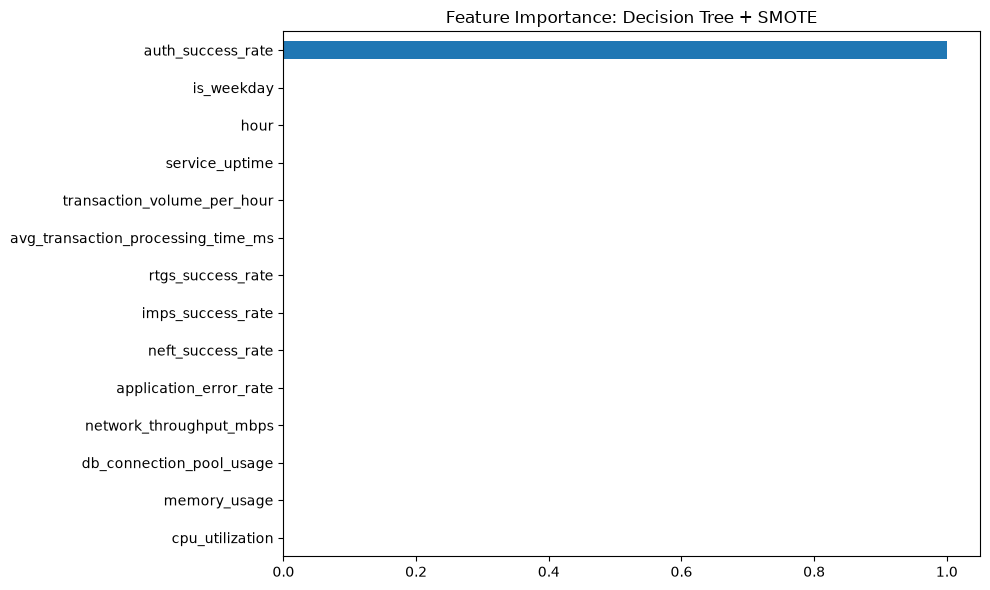

In [3]:
# SECTION 10: Incident classifier (binary, imbalanced)

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from imblearn.over_sampling import SMOTE

from imblearn.ensemble import BalancedRandomForestClassifier

from imblearn.pipeline import Pipeline

# Target: 1 = incident minute (auth drop with error spike), 0 = normal
infra["incident"] = infra["flag_auth_drop"].astype(int)

# Current-minute KPIs and load metrics as features
clf_features = ["cpu_utilization", "memory_usage", "db_connection_pool_usage", "network_throughput_mbps", "application_error_rate", "neft_success_rate", "imps_success_rate", "rtgs_success_rate", "avg_transaction_processing_time_ms", "auth_success_rate", "transaction_volume_per_hour", "service_uptime", "hour", "is_weekday"]

X = infra[clf_features]

y = infra["incident"]

print("Class balance :")
print(y.value_counts())

# Stratified split keeps the incident share equal in train and test
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Two imbalance strategies from the lessons
classifiers = {
    "Decision Tree + SMOTE": Pipeline([("scaler", StandardScaler()), ("smote", SMOTE(random_state=42)), ("classifier", DecisionTreeClassifier(max_depth=3, random_state=42))]),
    "Balanced Random Forest": Pipeline([("scaler", StandardScaler()), ("classifier", BalancedRandomForestClassifier(random_state=42, sampling_strategy="auto", replacement=False, bootstrap=True))])
}

# Train, score, and keep the model with the best incident F1
best_f1 = None
for name, pipe in classifiers.items():
    pipe.fit(X_train_c, y_train_c)
    y_pred = pipe.predict(X_test_c)
    acc = accuracy_score(y_test_c, y_pred)
    f1 = f1_score(y_test_c, y_pred)
    print()
    print("=====", name, "=====")
    print("Accuracy :", round(acc, 4), "| F1 (incident) :", round(f1, 4))
    print(classification_report(y_test_c, y_pred))
    print("Confusion matrix :")
    print(confusion_matrix(y_test_c, y_pred))
    if best_f1 is None or f1 > best_f1:
        best_f1 = f1
        best_classifier = pipe
        best_classifier_name = name

print()
print("Best classifier :", best_classifier_name, "| F1 :", round(best_f1, 4))

# Which features drive the best model
importances = pd.Series(best_classifier.named_steps["classifier"].feature_importances_, index=clf_features).sort_values()

plt.figure(figsize=(10, 6))
importances.plot(kind="barh")
plt.title("Feature Importance: " + best_classifier_name)
plt.tight_layout()
plt.show()

Contamination setting : 0.0174
Minutes flagged as anomalies : 176

Anomaly flags vs incident label
[[9850   55]
 [  54  121]]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      9905
           1       0.69      0.69      0.69       175

    accuracy                           0.99     10080
   macro avg       0.84      0.84      0.84     10080
weighted avg       0.99      0.99      0.99     10080

Average metrics: normal vs anomaly
anomaly                                   0        1
cpu_utilization                       48.93    60.08
memory_usage                          44.02    53.84
db_connection_pool_usage              39.15    48.19
network_throughput_mbps              244.17   304.63
application_error_rate                 1.94     5.43
neft_success_rate                     98.00    97.89
imps_success_rate                     99.01    99.03
rtgs_success_rate                     99.50    99.51
avg_transaction_processing_time_ms 

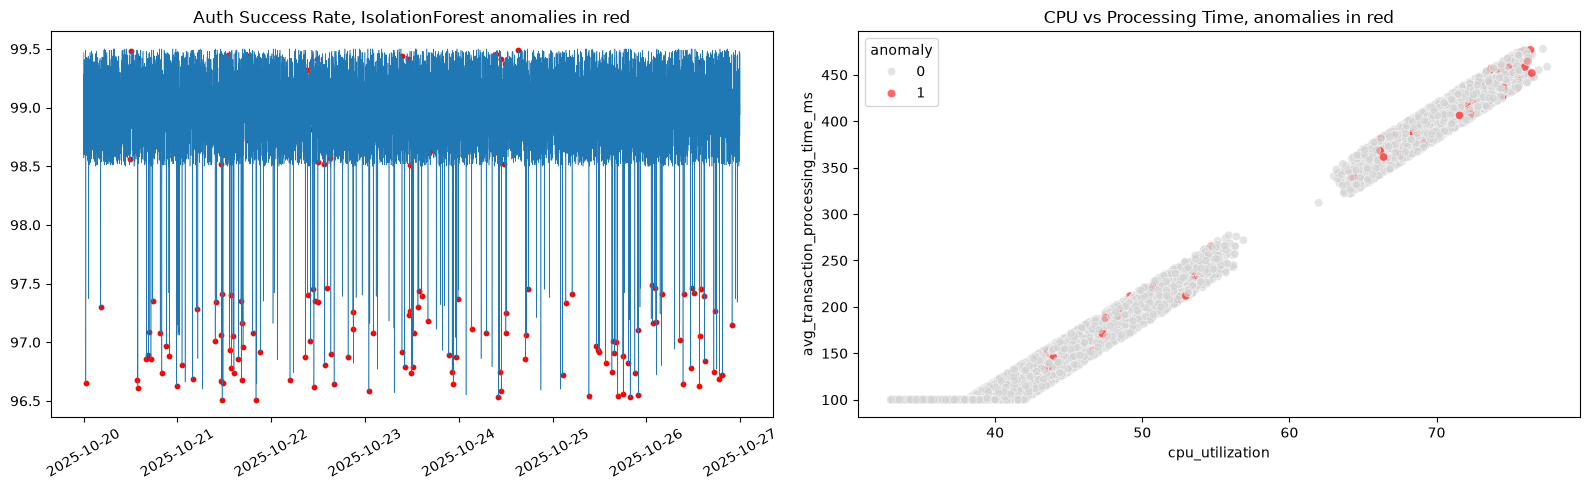

In [4]:
# SECTION 11: Anomaly detection with IsolationForest

from sklearn.ensemble import IsolationForest

from sklearn.pipeline import Pipeline as SkPipeline

# Metrics the detector watches (no labels used)
anomaly_features = ["cpu_utilization", "memory_usage", "db_connection_pool_usage", "network_throughput_mbps", "application_error_rate", "neft_success_rate", "imps_success_rate", "rtgs_success_rate", "avg_transaction_processing_time_ms", "auth_success_rate", "transaction_volume_per_hour", "service_uptime"]

# Expected anomaly share set to the observed incident rate
contamination = round(infra["incident"].mean(), 4)

print("Contamination setting :", contamination)

# Scale, then fit IsolationForest on all minutes
anomaly_model = SkPipeline([("scaler", StandardScaler()), ("detector", IsolationForest(n_estimators=200, contamination=contamination, random_state=42))])

anomaly_model.fit(infra[anomaly_features])

# -1 means anomaly, 1 means normal; convert to 1 and 0
infra["anomaly"] = (anomaly_model.predict(infra[anomaly_features]) == -1).astype(int)

print("Minutes flagged as anomalies :", infra["anomaly"].sum())

# How well unsupervised flags line up with known incidents
print()
print("Anomaly flags vs incident label")
print(confusion_matrix(infra["incident"], infra["anomaly"]))
print(classification_report(infra["incident"], infra["anomaly"]))

# What the flagged minutes look like compared with normal minutes
print("Average metrics: normal vs anomaly")
print(infra.groupby("anomaly")[anomaly_features].mean().round(2).T)

# Timeline and load view of flagged minutes
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(infra["timestamp"], infra["auth_success_rate"], linewidth=0.4)
flagged = infra[infra["anomaly"] == 1]
axes[0].scatter(flagged["timestamp"], flagged["auth_success_rate"], color="red", s=10)
axes[0].set_title("Auth Success Rate, IsolationForest anomalies in red")
axes[0].tick_params(axis="x", rotation=30)

sns.scatterplot(data=infra, x="cpu_utilization", y="avg_transaction_processing_time_ms", hue="anomaly", palette={0: "lightgray", 1: "red"}, alpha=0.6, ax=axes[1])
axes[1].set_title("CPU vs Processing Time, anomalies in red")

plt.tight_layout()
plt.show()

In [6]:
# SECTION 12: Save trained models with joblib

import os

import joblib

# Folder for saved models
os.makedirs("models", exist_ok=True)

# One file per forecasting model, compressed to keep files small
for target in forecast_targets:
    joblib.dump(best_forecasters[target], "models/forecast_" + target + ".joblib", compress=3)

# Incident classifier and anomaly detector pipelines
joblib.dump(best_classifier, "models/incident_classifier.joblib", compress=3)

joblib.dump(anomaly_model, "models/anomaly_detector.joblib", compress=3)

# Feature lists the API and dashboard need to call each model
model_config = {
    "forecast_targets": forecast_targets,
    "forecast_features": feature_cols,
    "classifier_features": clf_features,
    "anomaly_features": anomaly_features
}

joblib.dump(model_config, "models/model_config.joblib")

# Scored data for the dashboard (incident and anomaly columns included)
infra.to_csv("data/scored_infrastructure.csv", index=False)

# Reload a forecaster and the classifier to confirm the saved files work
reloaded = joblib.load("models/incident_classifier.joblib")

print("Reloaded classifier F1 :", round(f1_score(y_test_c, reloaded.predict(X_test_c)), 4))

reloaded_cpu = joblib.load("models/forecast_cpu_utilization.joblib")

print("Reloaded CPU forecaster RMSE :", round(np.sqrt(mean_squared_error(forecast_df["cpu_utilization"].iloc[split:], reloaded_cpu.predict(X_test))), 3))

# List saved files with sizes
print()
for name in sorted(os.listdir("models")):
    print(name, ":", round(os.path.getsize("models/" + name) / 1024, 1), "KB")

Reloaded classifier F1 : 1.0
Reloaded CPU forecaster RMSE : 3.122

anomaly_detector.joblib : 878.2 KB
forecast_avg_transaction_processing_time_ms.joblib : 12772.6 KB
forecast_cpu_utilization.joblib : 15911.0 KB
forecast_imps_success_rate.joblib : 1.4 KB
forecast_memory_usage.joblib : 15625.4 KB
forecast_neft_success_rate.joblib : 1.4 KB
forecast_rtgs_success_rate.joblib : 1.4 KB
incident_classifier.joblib : 13.8 KB
model_config.joblib : 1.4 KB
